# SnowPredict: predicting ski-area snow depth 30 days ahead

**Canvas project group 37** · Nat Toms, Owen Cruz-Abrams, Martha le Huray

This is our Milestone 2 notebook. It follows the order in the brief:

1. **Getting the data**: the downloads, and their total size
2. **Understanding the data**: what a row and each column are, shapes, types, summary statistics
3. **Cleaning and preprocessing**: each step, with a one-line reason
4. **The modelling table**: target, features, and the split by winter
5. **The revised project question**

Decision IDs such as **D-017** refer to `docs/DECISIONS.md`, which records the options we considered and why we chose
each one. Facts about the APIs, with the exact queries, are in `docs/DATA_SOURCES.md`. Reusable code lives in `src/`
and is unit-tested in `tests/` (`uv run pytest -q`).

In [1]:
import os, sys
from pathlib import Path
os.environ.setdefault("SNOWPREDICT_OFFLINE", "1")   # every raw file is cached in data/raw; set "0" to download missing ones
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import clean, lineage, modeltable as mt, parse, sites, sources, verify_raw

pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 100)
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 14, "axes.labelsize": 12, "legend.fontsize": 11})
OUT, FIG = ROOT / "data" / "processed", ROOT / "figures"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(exist_ok=True)

def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)

ELEMENTS = sites.SNOTEL_ELEMENTS                      # SNWD, WTEQ, TAVG, TMAX, TMIN, PREC, PRCP
CAND = list(sites.CANDIDATE_STATIONS)                 # the 20 SNOTEL stations we examined
RES = sites.RESORTS                                   # the 3 resorts we model
STATIONS = [t for r in RES.values() for t in r["stations"]]

## 1. Getting the data

| Source | What we use it for | Link |
|---|---|---|
| **Open-Meteo Historical Weather API** (ERA5 and ERA5-Land reanalysis) | weather inputs (features) | https://open-meteo.com/en/docs/historical-weather-api |
| **NRCS SNOTEL**, via the AWDB REST API | measured snow depth at mountain stations (the target) | https://wcc.sc.egov.usda.gov/awdbRestApi/swagger-ui/index.html |

Every download goes through `src/lineage.py::fetch()`. It saves the raw response **unchanged** under `data/raw/` and
logs the URL, time, size and SHA-256 hash in `data/raw/MANIFEST.csv`. Re-running reads the saved file, so results do not
change if an API does. The requests themselves are defined once, in `src/sources.py`.

### 1.1 SNOTEL stations
We examined 20 candidate stations (`src/sites.py`): ten active stations within about 40 km of Aspen (DATA_SOURCES §2.1),
plus stations on or next to ten other ski areas. Coordinates and elevations come from the API's station metadata, never typed by hand.

In [2]:
meta = (pd.DataFrame(sources.station_metadata()).set_index("stationTriplet").loc[CAND]
        [["name", "stateCode", "elevation", "latitude", "longitude"]])
meta["group"] = pd.Series(sites.CANDIDATE_STATIONS)
meta["elev_m"] = (meta.elevation * 0.3048).round()
meta

,name,stateCode,elevation,latitude,longitude,group,elev_m
stationTriplet,,,,,,,
542:CO:SNTL,Independence Pass,CO,10570.0,39.07543,-106.61154,Aspen area,3222.0
556:CO:SNTL,Kiln,CO,9610.0,39.31720,-106.61501,Aspen area,2929.0
369:CO:SNTL,Brumley,CO,10570.0,39.08758,-106.54231,Aspen area,3222.0
547:CO:SNTL,Ivanhoe,CO,10540.0,39.29228,-106.54907,Aspen area,3213.0
658:CO:SNTL,Nast Lake,CO,8710.0,39.29695,-106.60786,Aspen area,2655.0
737:CO:SNTL,Schofield Pass,CO,10640.0,39.01467,-107.04933,Aspen area,3243.0
669:CO:SNTL,North Lost Trail,CO,9190.0,39.07818,-107.14388,Aspen area,2801.0
380:CO:SNTL,Butte,CO,10190.0,38.89435,-106.95327,Aspen area,3106.0
1101:CO:SNTL,Chapman Tunnel,CO,10090.0,39.26210,-106.62944,Aspen area,3075.0


### 1.2 SNOTEL daily data
One request per station, for its full record: snow depth `SNWD`, snow-water equivalent `WTEQ`, air temperature
`TAVG/TMAX/TMIN`, and precipitation (`PREC` accumulated since Oct 1, `PRCP` daily). Request choices (D-009):
- `returnFlags=true` and `returnOriginalValues=true` give NRCS's quality flags and each value as it was **before** NRCS edited it.
- `returnSuspectData=true`: the default (`false`) silently drops values NRCS marked suspect. We want to see them and remove them ourselves (§3.3).
- We never request NRCS's 30-year normals. They include our test winters, which would leak into the baseline (D-010).

In [3]:
sn = pd.concat([sources.snotel_daily(t) for t in CAND], ignore_index=True)
print(sn.shape)
sn.head()

(1756280, 9)


,station,element,date,value,qc_flag,qa_flag,orig_value,orig_qc_flag,unit
0,542:CO:SNTL,PRCP,1980-07-31,NaN,M,U,0.0,T,in
1,542:CO:SNTL,PRCP,1980-08-01,NaN,M,U,0.0,T,in
2,542:CO:SNTL,PRCP,1980-08-02,NaN,M,U,0.0,T,in
3,542:CO:SNTL,PRCP,1980-08-03,NaN,M,U,0.0,T,in
4,542:CO:SNTL,PRCP,1980-08-04,NaN,M,U,0.0,T,in


### 1.3 Open-Meteo: pin the model, and what `elevation=` does
Open-Meteo's default `models=best_match` lets the API choose the underlying dataset. Below, at Aspen Mountain, we compare
it with two pinned models.

share of days on which best_match equals each model:


time,2013,2014,2015,2016,2017,2018,2019,2020
era5_land,1.0,1.0,1.0,1.0,0.02,0.03,0.02,0.04
ecmwf_ifs,0.0,0.0,0.0,0.0,1.00,1.00,1.00,1.00


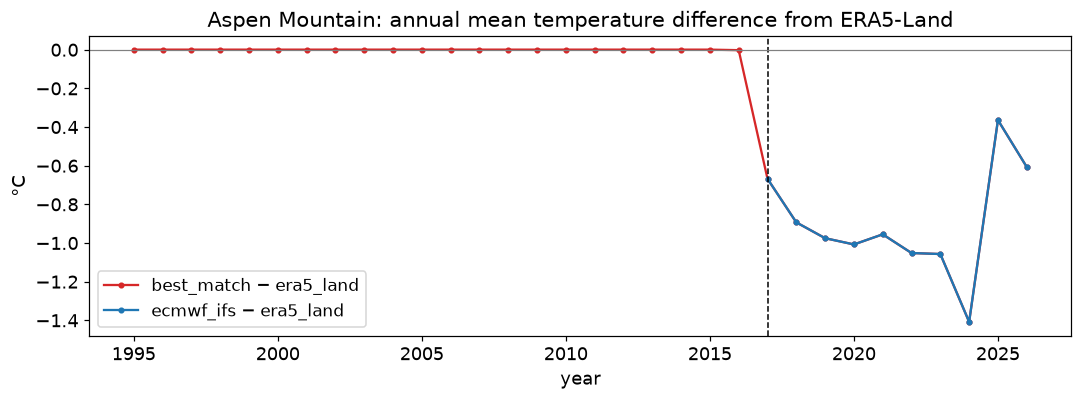

In [4]:
ASPEN = sites.SKI_AREAS["Aspen Mountain"]

def aspen_tmean(model):
    p = dict(latitude=ASPEN[0], longitude=ASPEN[1], start_date="1995-01-01", end_date="2026-10-31",
             daily=["temperature_2m_mean"], models=model, timezone="auto")
    return parse.open_meteo_daily(lineage.open_meteo(p, name=f"series_aspen_{model}"))["temperature_2m_mean"]

tm = pd.DataFrame({m: aspen_tmean(m) for m in ["best_match", "era5_land", "ecmwf_ifs"]})
same = pd.DataFrame({m: (tm.best_match - tm[m]).abs().lt(0.05).groupby(tm.index.year).mean() for m in ["era5_land", "ecmwf_ifs"]})
print("share of days on which best_match equals each model:")
display(same.loc[2013:2020].round(2).T)

fig, ax = plt.subplots(figsize=(10, 3.8))
for m, c in [("best_match", "tab:red"), ("ecmwf_ifs", "tab:blue")]:
    diff = (tm[m] - tm.era5_land).groupby(tm.index.year).mean()
    ax.plot(diff.index, diff.values, "-o", ms=3, color=c, label=f"{m} − era5_land")
ax.axvline(2017, color="k", ls="--", lw=1); ax.axhline(0, color="grey", lw=.8)
ax.set_title("Aspen Mountain: annual mean temperature difference from ERA5-Land"); ax.set_xlabel("year"); ax.set_ylabel("°C")
ax.legend(); fig.tight_layout(); savefig(fig, "best_match_break"); plt.show()

**Finding (D-002).** `best_match` is ERA5-Land up to 2016 and ECMWF IFS from 2017. At the switch, its temperature
shifts by about 1 °C at Aspen (colder), and by several °C at St. Anton, the site in our original proposal (warmer;
DATA_SOURCES §1.3). Our validation and test winters are the later ones, so this fake break would sit right at the
train/validation boundary (2017).
**We always pin the model and never use `best_match`.**

Next: what the `elevation=` parameter changes. Without it, the API uses the grid cell's average terrain height (the "default" row).

In [5]:
def at_elevation(e):
    p = dict(latitude=ASPEN[0], longitude=ASPEN[1], start_date="2020-01-15", end_date="2020-01-15", models="era5_seamless",
             timezone="auto", daily=["temperature_2m_mean", "snowfall_sum", "snow_depth_mean", "precipitation_sum"])
    if e is not None:
        p["elevation"] = e
    j = lineage.open_meteo(p, name=f"elev_aspen_{e}")
    return {"requested elevation": e or "default", "elevation used (m)": j["elevation"],
            **{k: v[0] for k, v in j["daily"].items() if k != "time"}}

pd.DataFrame([at_elevation(e) for e in [None, 2400, 3000, 3400]]).set_index("requested elevation")

,elevation used (m),temperature_2m_mean,snowfall_sum,snow_depth_mean,precipitation_sum
requested elevation,,,,,
default,2423.0,-6.5,0.0,0.69,0.0
2400,2400.0,-6.3,0.0,0.69,0.0
3000,3000.0,-10.2,0.0,0.69,0.0
3400,3400.0,-12.2,0.0,0.73,0.0


**Finding (D-003, D-005).** Temperature follows the requested elevation (−6.3 °C at 2,400 m, −12.2 °C at 3,400 m), but
snowfall and precipitation do not change, and snow depth barely does. In reanalysis, snow is a property of the whole grid
cell (9–25 km), so it cannot tell a valley from a summit. ERA5-Land snow depth is also biased low at most candidate
stations (−4 % to −59 %), and too high at a few low or sheltered ones (DATA_SOURCES §4). So **the target is snow depth measured on the mountain by SNOTEL**,
and Open-Meteo supplies the weather inputs.

Open-Meteo has no archived 30-day forecasts before 2025, so we cannot compare against a real forecast. Our
baselines are climatology and persistence (D-004; DATA_SOURCES §1.5).

### 1.4 Open-Meteo weather inputs for the modelled stations
For each of the four modelled SNOTEL stations (§2.2), we request daily values at the station's own lat/lon and elevation,
with `timezone=auto` so that each day is a local calendar day (D-027):
- **ERA5** (0.25° grid): temperature, precipitation, snowfall, sunshine, wind, cloud, humidity, pressure (10 variables).
- **ERA5-Land** (0.1° grid): temperature, plus its own modelled snow depth, used as a feature only.

The requests cover 1997-07-01 to 2026-06-30 in 5-year chunks: 4 stations × 2 models × 6 chunks = 48 files.
`scripts/prefetch_features.py` downloaded them unattended, because of Open-Meteo's rate limits (D-028).

In [6]:
F = {t: sources.fetch_station(t, meta.loc[t, "latitude"], meta.loc[t, "longitude"], meta.loc[t, "elevation"] * 0.3048)
     for t in STATIONS}
{meta.loc[t, "name"]: df.shape for t, df in F.items()}

{'Kiln': (10592, 14),
 'Brumley': (10592, 14),
 'Brighton': (10592, 14),
 'Heavenly Valley': (10592, 14)}

### 1.5 Total size, and integrity
Every raw file, and how large it is. `verify_raw` re-hashes each file and stops the notebook if any file differs
from what was downloaded, or if a file is not in the manifest.

In [7]:
man = lineage.manifest()
cached = man[man.file.fillna("") != ""].drop_duplicates("url", keep="last")
print(f"Total raw data: {cached.bytes.sum() / 1e6:.1f} MB in {len(cached)} files")
display(cached.groupby("source").agg(files=("file", "size"), MB=("bytes", lambda b: round(b.sum() / 1e6, 1))))
assert verify_raw.main() == 0

Total raw data: 163.1 MB in 135 files


,files,MB
source,,
open_meteo,109,13.0
snotel,24,148.9
snotel_report_generator,2,1.2


135 cached files checked, 0 problem(s)



## 2. Understanding the data
### 2.1 SNOTEL: the raw table
As downloaded, **one row = one station, one element (variable), one day**. Columns:

| column | meaning |
|---|---|
| `station` | SNOTEL station ID, written `id:state:network` (e.g. `556:CO:SNTL`) |
| `element` | the variable: `SNWD`, `WTEQ`, `TAVG`, `TMAX`, `TMIN`, `PREC`, `PRCP` |
| `date` | the day. For snow depth, the value is the reading at the **end** of that day (DATA_SOURCES §5) |
| `value` | NRCS's current value, in source units: inches, or °F for temperatures |
| `qc_flag`, `qa_flag` | NRCS quality-control and quality-assurance flags (§3.3) |
| `orig_value`, `orig_qc_flag` | the value and flag **before** NRCS edited it |
| `unit` | source unit |

In [8]:
display(sn.dtypes.to_frame("dtype").T)
sn.groupby("element")["value"].describe().round(1)

,station,element,date,value,qc_flag,qa_flag,orig_value,orig_qc_flag,unit
dtype,str,str,datetime64[us],float64,str,str,float64,str,str


,count,mean,std,min,25%,50%,75%,max
element,,,,,,,,
PRCP,284562.0,0.1,0.3,-2.0,0.0,0.0,0.1,9.0
PREC,284573.0,22.3,19.0,0.0,8.5,18.8,29.6,134.0
SNWD,170112.0,23.3,29.6,-65.0,0.0,10.0,40.0,199.0
TAVG,241477.0,35.4,27.3,-95.4,23.2,34.9,48.4,4178.5
TMAX,241195.0,48.7,27.5,-147.8,34.7,48.2,63.3,4178.5
TMIN,241423.0,24.8,27.6,-399.1,13.5,26.1,36.5,4178.5
WTEQ,285421.0,7.8,11.8,0.0,0.0,2.5,11.6,116.5


For cleaning, we reshape so that **one row = one station on one day**. Each variable gets four columns: the value,
its two NRCS flags, and its original reading. The summary already shows impossible values, all dealt with in §3: snow
depth around −65 in, temperatures of thousands of °F, and negative daily precipitation.

In [9]:
w = clean.long_to_wide(sn, ELEMENTS)
print("one row per station-day:", w.shape)
w[ELEMENTS].describe().T.round(1)

one row per station-day: (285740, 28)


,count,mean,std,min,25%,50%,75%,max
SNWD,170112.0,23.3,29.6,-65.0,0.0,10.0,40.0,199.0
WTEQ,285421.0,7.8,11.8,0.0,0.0,2.5,11.6,116.5
TAVG,241477.0,35.4,27.3,-95.4,23.2,34.9,48.4,4178.5
TMAX,241195.0,48.7,27.5,-147.8,34.7,48.2,63.3,4178.5
TMIN,241423.0,24.8,27.6,-399.1,13.5,26.1,36.5,4178.5
PREC,284573.0,22.3,19.0,0.0,8.5,18.8,29.6,134.0
PRCP,284562.0,0.1,0.3,-2.0,0.0,0.0,0.1,9.0


### 2.2 How many winters of measured snow depth? Choosing the resorts
A station has a **good winter** when at least 100 of the ~121 Dec–Mar days have a snow-depth value. Station metadata
dates are unreliable in both directions, so we count actual values.

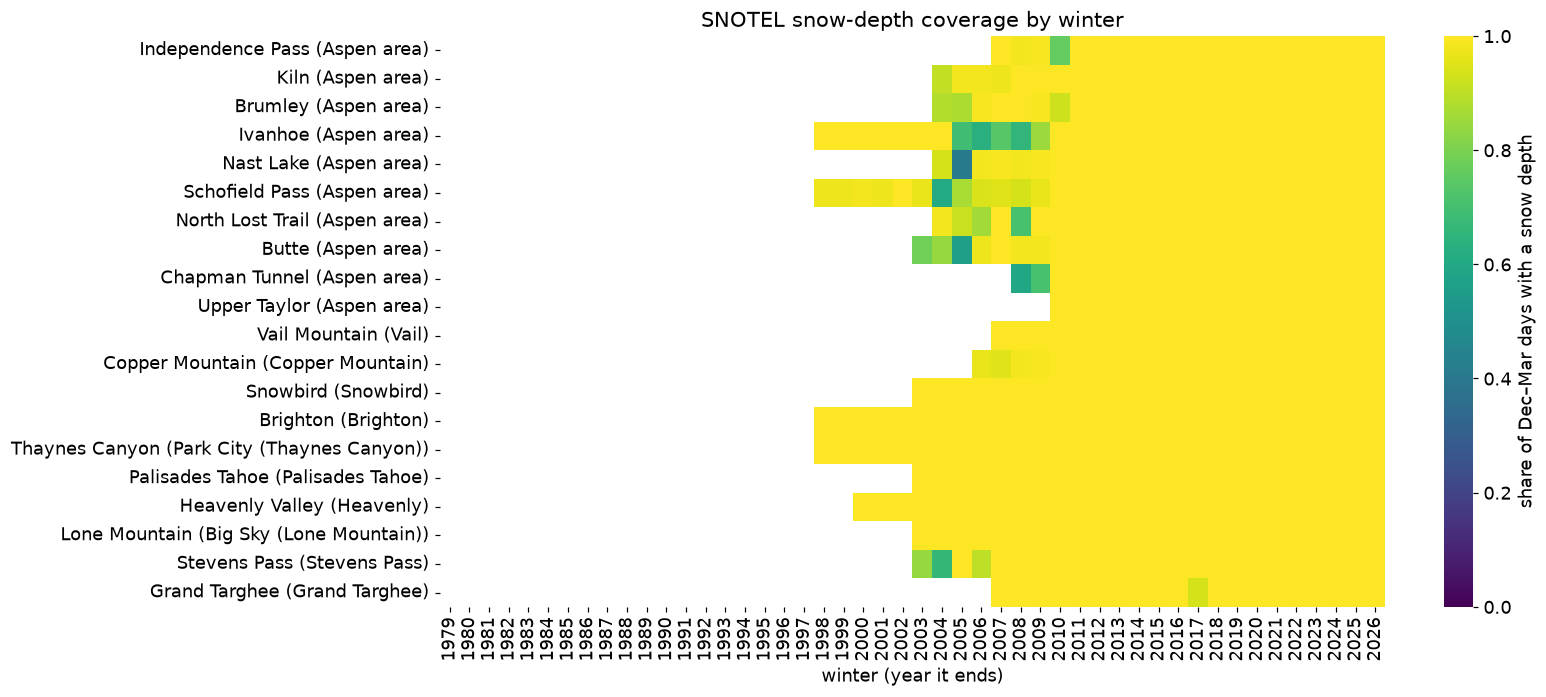

,name,group,elev_m,good_winters,first_good_winter
stationTriplet,,,,,
542:CO:SNTL,Independence Pass,Aspen area,3222.0,19,2007
556:CO:SNTL,Kiln,Aspen area,2929.0,23,2004
369:CO:SNTL,Brumley,Aspen area,3222.0,23,2004
547:CO:SNTL,Ivanhoe,Aspen area,3213.0,25,1998
658:CO:SNTL,Nast Lake,Aspen area,2655.0,22,2004
737:CO:SNTL,Schofield Pass,Aspen area,3243.0,28,1998
669:CO:SNTL,North Lost Trail,Aspen area,2801.0,22,2004
380:CO:SNTL,Butte,Aspen area,3106.0,22,2004
1101:CO:SNTL,Chapman Tunnel,Aspen area,3075.0,17,2010


In [10]:
dec_mar = sn[sn.date.dt.month.isin([12, 1, 2, 3]) & (sn.element == "SNWD")].dropna(subset=["value"])
days = dec_mar.groupby(["station", parse.winter_of(dec_mar.date)]).size().unstack().reindex(index=CAND, columns=range(1979, 2027))
good = days.ge(100)
first_good = good.idxmax(axis=1).where(good.any(axis=1))

fig, ax = plt.subplots(figsize=(15, 6.5))
sns.heatmap((days / 121).clip(upper=1).set_axis([f"{meta.loc[t, 'name']} ({meta.loc[t, 'group']})" for t in CAND]),
            cmap="viridis", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "share of Dec–Mar days with a snow depth"})
ax.set_title("SNOTEL snow-depth coverage by winter"); ax.set_xlabel("winter (year it ends)"); ax.set_ylabel("")
fig.tight_layout(); savefig(fig, "snow_depth_coverage"); plt.show()
meta[["name", "group", "elev_m"]].assign(good_winters=good.sum(axis=1), first_good_winter=first_good)

**Finding (D-005, D-006).** SWE and temperature records go back to about 1980 (DATA_SOURCES §2.1), but snow-depth sensors were added only in
1997–2010, so we have 17–29 winters per station.

**Our three resorts (D-007, D-008).** We picked three distinct snow climates, each with a long record at a station on
or next to the resort:

| Resort | Station(s) | Winters | Climate |
|---|---|---|---|
| **Aspen**, CO | Kiln + Brumley, combined (§4.1) | 2004–2026 | continental |
| **Brighton**, UT | Brighton | 1998–2026 | intermountain |
| **Heavenly**, CA | Heavenly | 2000–2026 | Sierra, on the lee side of Lake Tahoe |

No SNOTEL station sits on an Aspen ski area. Kiln and Brumley are the only nearby stations with every winter from 2004.
Averaging the two, only on days both report, gives a stable Aspen-area series.

### 2.3 Open-Meteo: the weather table
**One row = one day at one station.** Columns are named `<model>__<variable>`, in source units:

| variable | meaning | unit |
|---|---|---|
| `temperature_2m_max/min/mean` | air temperature 2 m above ground (ERA5 and ERA5-Land) | °C |
| `precipitation_sum`, `snowfall_sum` | daily precipitation; daily snowfall | mm; cm |
| `sunshine_duration` | time with direct sunshine | s |
| `wind_speed_10m_max` | maximum wind speed 10 m above ground | km/h |
| `cloud_cover_mean`, `relative_humidity_2m_mean` | daily mean cloud cover; relative humidity | % |
| `pressure_msl_mean` | mean sea-level pressure | hPa |
| `snow_depth_mean` | ERA5-Land modelled snow depth (feature only) | m |

In [11]:
kiln = F["556:CO:SNTL"]
print(kiln.shape, "| dtypes:", kiln.dtypes.value_counts().to_dict())
kiln.describe().T[["mean", "min", "max"]].round(1)

(10592, 14) | dtypes: {dtype('float64'): 12, dtype('int64'): 2}


,mean,min,max
era5__temperature_2m_max,8.3,-18.7,27.2
era5__temperature_2m_min,-4.3,-32.2,11.8
era5__temperature_2m_mean,2.0,-23.8,19.1
era5__precipitation_sum,1.9,0.0,45.4
era5__snowfall_sum,0.7,0.0,20.1
era5__sunshine_duration,39892.3,0.0,51849.4
era5__wind_speed_10m_max,14.8,3.9,32.1
era5__cloud_cover_mean,49.5,0.0,100.0
era5__relative_humidity_2m_mean,65.3,23.0,98.0
era5__pressure_msl_mean,1018.7,992.2,1043.4


## 3. Cleaning and preprocessing
We clean all 20 candidate stations (D-025), so the clean table supports any station choice. Every rule runs in
source units (inches, °F). Each rule records its ID in `<var>_clean_flag`, prints how many rows it changed, and adds a
row to `data/processed/cleaning_log.csv`. The key thresholds come from distributions shown here; for the others, the
evidence is in the rule's `reason` and in the cited decision (D-016 to D-021).

The thresholds were chosen on all winters, including the test winters. The rules are applied identically to every
winter and never see the target, but we disclose it (D-039).

In [12]:
LOG = []
def log(step, rule, column, n, action, reason):
    LOG.append(dict(step=step, rule=rule, column=column, n_affected=int(n), action=action, reason=reason))
    print(f"[{step}] {rule} | {column}: {int(n):,} rows -> {action}")

def mark(mask, col, flag, value=np.nan):
    """Set w[col] to `value` where mask is True (value=None: flag only), and record the rule in <col>_clean_flag."""
    if value is not None:
        w.loc[mask, col] = value
    w.loc[mask, f"{col}_clean_flag"] += flag + ";"

### 3.1 Complete the calendar (D-023)
A day the API did not return is *absent*, not `NaN`. Each station gets a continuous daily calendar, so missing days
become explicit rows that can be counted.

In [13]:
n_before = len(w)
w = clean.complete_calendar(w)
log("3.1", "complete daily calendar", "all", len(w) - n_before, "insert NaN rows",
    "absent days must exist as rows before missingness can be measured")
dates = w.index.get_level_values("date")
w["winter"], w["water_year"] = parse.winter_of(dates), clean.water_year(dates)
w["in_season"], w["month"] = clean.in_season(dates), dates.month

[3.1] complete daily calendar | all: 38 rows -> insert NaN rows


### 3.2 Missing data: how much, and is there a pattern?
Days before a sensor's first valid reading are **not yet installed**: structural, not missing. Everything after that is
**missing while installed**, which is the real missing data.

In [14]:
def installed(e):
    return w[e].notna().groupby(level="station").cummax()

rows = []
for e in ELEMENTS:
    inst = installed(e)
    rows.append({"element": e, "% rows NaN (all)": 100 * w[e].isna().mean(), "% not yet installed": 100 * (~inst).mean(),
                 "% missing while installed": 100 * w.loc[inst, e].isna().mean(),
                 "% missing while installed, Nov–Apr": 100 * w.loc[inst & w.in_season, e].isna().mean()})
miss_raw = pd.DataFrame(rows).set_index("element").round(2)
miss_raw

,% rows NaN (all),% not yet installed,% missing while installed,"% missing while installed, Nov–Apr"
element,,,,
SNWD,40.47,39.76,1.19,1.36
WTEQ,0.12,0.11,0.01,0.02
TAVG,15.50,14.07,1.66,1.47
TMAX,15.60,14.07,1.78,1.61
TMIN,15.52,14.07,1.68,1.47
PREC,0.42,0.40,0.02,0.04
PRCP,0.43,0.40,0.02,0.04


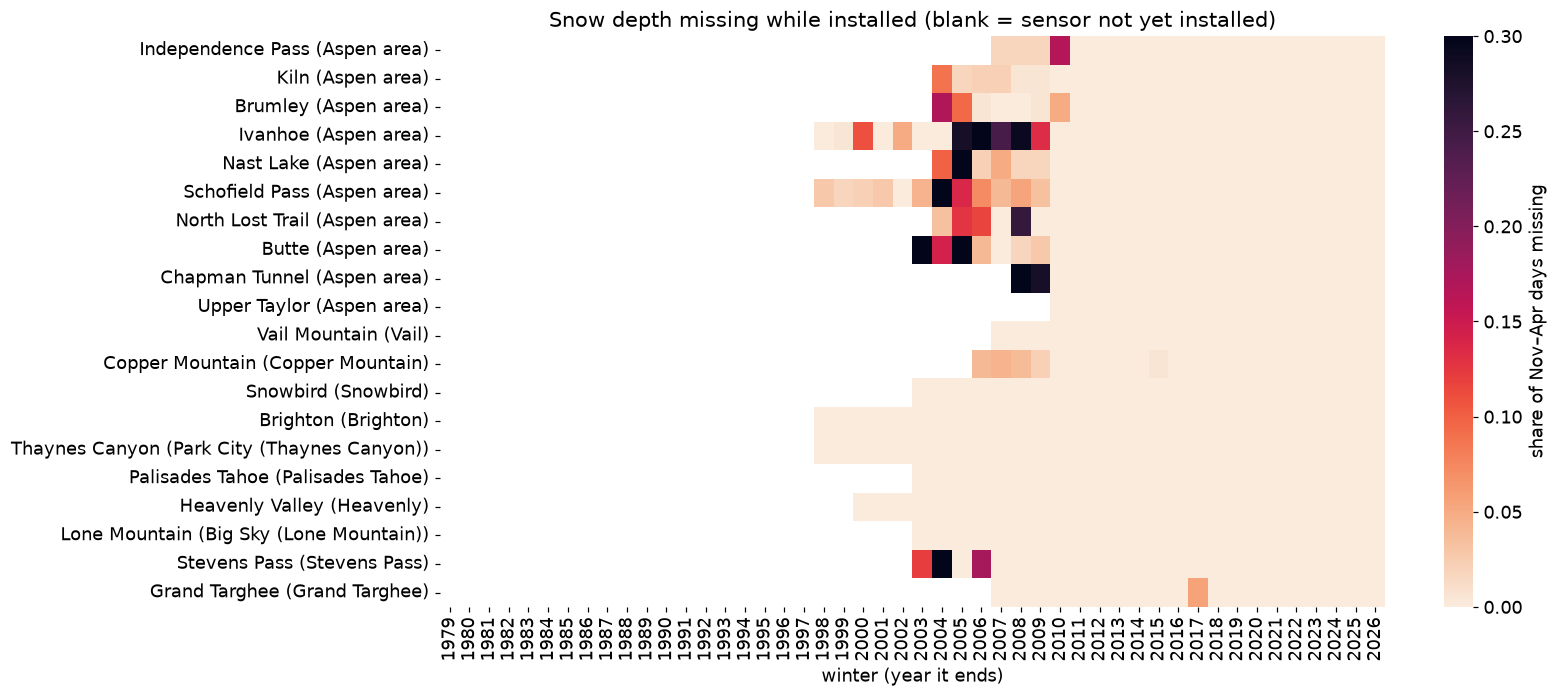

NRCS flag on rows where snow depth is missing: {'S': 1329, '(no record returned)': 714}
Temperature also missing on 35% of those days
Mean depth the day before a gap: 42.1 in; all in-season days: 41.1 in


In [15]:
inst = installed("SNWD")
m = w[inst & w.in_season].assign(miss=lambda d: d.SNWD.isna())
grid = m.groupby([m.index.get_level_values("station"), "winter"]).miss.mean().unstack().reindex(index=CAND, columns=range(1979, 2027))
grid.index = [f"{meta.loc[t, 'name']} ({meta.loc[t, 'group']})" for t in CAND]
fig, ax = plt.subplots(figsize=(15, 6.5))
sns.heatmap(grid, cmap="rocket_r", vmin=0, vmax=0.3, ax=ax, mask=grid.isna(), cbar_kws={"label": "share of Nov–Apr days missing"})
ax.set_title("Snow depth missing while installed (blank = sensor not yet installed)"); ax.set_xlabel("winter (year it ends)"); ax.set_ylabel("")
fig.tight_layout(); savefig(fig, "snow_depth_missingness"); plt.show()

mi = w[inst].assign(miss=lambda d: d.SNWD.isna())
print("NRCS flag on rows where snow depth is missing:", mi[mi.miss].SNWD_nrcs_qc.fillna("(no record returned)").value_counts().to_dict())
print(f"Temperature also missing on {100 * mi.loc[mi.miss, 'TAVG'].isna().mean():.0f}% of those days")
prev = mi.groupby(level="station").SNWD.shift(1)
print(f"Mean depth the day before a gap: {prev[mi.miss & mi.in_season].mean():.1f} in; all in-season days: {mi.loc[mi.in_season, 'SNWD'].mean():.1f} in")

**What this shows.**
- About 40 % of snow-depth rows are NaN, but nearly all of those are days before the sensor existed. Missing while installed is only about 1 %.
- The gaps cluster in each sensor's first few winters (about 2003–2010) and are near zero after about 2011. That looks
  like early sensor problems, not weather.
- About two-thirds of gaps carry NRCS flag **S** (NRCS removed the reading as suspect). On the rest, the API returned no snow-depth record that day.
- The depth just before a gap is close to the average depth. This is only a descriptive check: it does not prove that gaps are unrelated to snow depth.

Missing values are handled in §3.5: short gaps are filled causally, and long gaps stay missing.

### 3.3 NRCS quality flags (D-016)
QC flags: **V** valid · **E** edited · **K** estimate · **S** suspect · **C** correction equation applied · **N** no
validation profile. Two flags, **G** and **T**, appear in the data but are not in NRCS's published list.

In [16]:
display(sn.assign(qc=sn.qc_flag.fillna("∅")).groupby(["element", "qc"]).size().unstack(fill_value=0))
s_rows = sn[sn.qc_flag == "S"]
print("Suspect (S) rows:", len(s_rows), "| still carrying a value:", s_rows.value.notna().sum())
print("Original readings behind snow-depth S rows (in):", s_rows[s_rows.element == "SNWD"].orig_value.describe().round(1).to_dict())

qc,C,E,G,K,M,N,S,T,V
element,,,,,,,,,
PRCP,0,121195,0,199,1002,0,363,0,162805
PREC,0,91701,0,200,45,0,1256,0,192380
SNWD,0,52844,0,472,0,0,1834,0,116683
TAVG,137011,798,7,9,267,58,1276,0,103102
TMAX,136660,762,7,9,218,6,1605,0,103260
TMIN,136999,770,7,9,225,6,1403,0,103111
WTEQ,0,123784,0,437,34,0,261,523,160677


Suspect (S) rows: 7998 | still carrying a value: 2272
Original readings behind snow-depth S rows (in): {'count': 1834.0, 'mean': 80.8, 'std': 107.0, 'min': -280.0, '25%': 0.0, '50%': 47.0, '75%': 194.0, 'max': 269.0}


In [17]:
for e in ELEMENTS:
    w[f"{e}_clean_flag"], w[f"{e}_imputed"] = "", False
for e in ELEMENTS:
    msk = (w[f"{e}_nrcs_qc"] == "S") & w[e].notna()
    mark(msk, e, "S")
    log("3.3", "NRCS QC flag S (suspect) still carrying a value", e, msk.sum(), "set NaN",
        "NRCS judged the reading suspect; the original is preserved in *_nrcs_orig")
log("3.3", "NRCS QC flag S with value already null", "all", (sn.qc_flag.eq("S") & sn.value.isna()).sum(), "keep NaN",
    "NRCS removed the value; we do NOT restore the original (originals behind S include physically impossible values, e.g. ±200 in)")
log("3.3", "NRCS QC flags E/K/C (edited, estimated, corrected)", "all", sn.qc_flag.isin(["E", "K", "C"]).sum(), "keep",
    "NRCS corrections fix known sensor errors; flags kept per row so models can test sensitivity")
log("3.3", "undocumented flags G/T", "TAVG/TMAX/TMIN/WTEQ", sn.qc_flag.isin(["G", "T"]).sum(), "keep flag; values judged by §3.4 rules",
    "not in NRCS flag list; G rows (Vail 1985) contain ~3000 °F and are removed by the physical bounds in §3.4")

[3.3] NRCS QC flag S (suspect) still carrying a value | SNWD: 113 rows -> set NaN
[3.3] NRCS QC flag S (suspect) still carrying a value | WTEQ: 0 rows -> set NaN
[3.3] NRCS QC flag S (suspect) still carrying a value | TAVG: 492 rows -> set NaN
[3.3] NRCS QC flag S (suspect) still carrying a value | TMAX: 491 rows -> set NaN
[3.3] NRCS QC flag S (suspect) still carrying a value | TMIN: 521 rows -> set NaN
[3.3] NRCS QC flag S (suspect) still carrying a value | PREC: 292 rows -> set NaN
[3.3] NRCS QC flag S (suspect) still carrying a value | PRCP: 363 rows -> set NaN
[3.3] NRCS QC flag S with value already null | all: 5,726 rows -> keep NaN
[3.3] NRCS QC flags E/K/C (edited, estimated, corrected) | all: 803,859 rows -> keep
[3.3] undocumented flags G/T | TAVG/TMAX/TMIN/WTEQ: 544 rows -> keep flag; values judged by §3.4 rules


### 3.4 Unusual values
**(a) Negative snow depth (D-020).** Small negatives in [−4, 0) in are a zero offset on bare ground, so they become 0.
Anything below −4 in is impossible, so it becomes NaN. All raw negatives were already flagged S and removed in §3.3, so
this rule stays as a guard and changes 0 rows.

In [18]:
m_small, m_big = (w.SNWD < 0) & (w.SNWD >= -4), w.SNWD < -4
mark(m_small, "SNWD", "neg_offset", 0.0)
log("3.4", "SNWD in [-4, 0) in", "SNWD", m_small.sum(), "set 0", "ultrasonic zero-offset: small negatives cluster at -2..-4 in on bare ground")
mark(m_big, "SNWD", "neg_large")
log("3.4", "SNWD < -4 in", "SNWD", m_big.sum(), "set NaN", "impossible; values ~ -60 in are sensor errors")

[3.4] SNWD in [-4, 0) in | SNWD: 0 rows -> set 0
[3.4] SNWD < -4 in | SNWD: 0 rows -> set NaN


**(b) Short spikes (D-017).** We compare each day with the centred 7-day rolling median. A storm or melt-out is a
*step*, which the median follows within 3 days. A sensor spike that reverts leaves a large residual. The threshold sits
in the gap of the residual distribution.

SNWD,"(-300, -30]","(-30, -20]","(-20, -12]","(-12, -6]","(-6, 6]","(6, 12]","(12, 20]","(20, 30]","(30, 300]"
days,21,2,7,141,0,838,46,5,2


[3.4] |SNWD - rolling median(7d)| > 20 in | SNWD: 28 rows -> set NaN


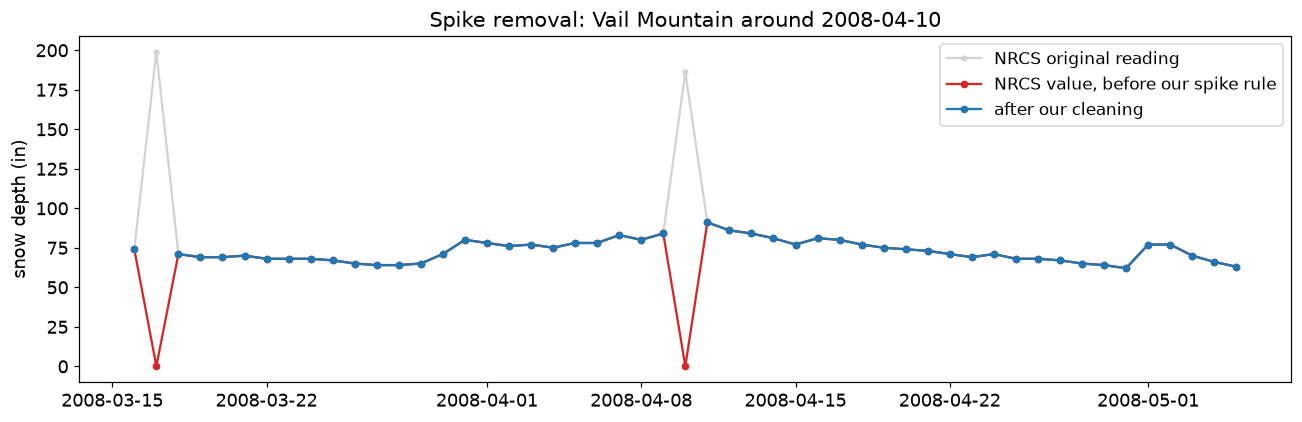

[3.4] |WTEQ - rolling median(7d)| > 5 in | WTEQ: 2 rows -> set NaN


In [19]:
res = clean.rolling_median_residual(w.SNWD, 7)
display(pd.cut(res[res.abs() > 6], [-300, -30, -20, -12, -6, 6, 12, 20, 30, 300]).value_counts().sort_index().to_frame("days").T)
spk = res.abs() > 20
pre_spike = w.SNWD.copy()
mark(spk, "SNWD", "spike")
log("3.4", "|SNWD - rolling median(7d)| > 20 in", "SNWD", spk.sum(), "set NaN",
    "residual histogram has its minimum in the 20–30 in bin, between storm/settlement deviations (≤20 in) and the spike tail (>30 in); 99.99th pct = 37 in")

st, day = res[spk].abs().idxmax()                   # the largest spike we removed, ±25 days
d = pd.DataFrame({"orig": w.SNWD_nrcs_orig, "nrcs": pre_spike, "clean": w.SNWD}).loc[st].loc[day - pd.Timedelta(days=25):day + pd.Timedelta(days=25)]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(d.index, d.orig, "o-", ms=3, color="lightgrey", label="NRCS original reading")
ax.plot(d.index, d.nrcs, "o-", ms=4, color="tab:red", label="NRCS value, before our spike rule")
ax.plot(d.index, d.clean, "o-", ms=4, color="tab:blue", label="after our cleaning")
ax.set_title(f"Spike removal: {meta.loc[st, 'name']} around {day.date()}"); ax.set_ylabel("snow depth (in)"); ax.legend()
fig.tight_layout(); savefig(fig, "spike_example"); plt.show()

rw = clean.rolling_median_residual(w.WTEQ, 7)
m = rw.abs() > 5
mark(m, "WTEQ", "spike")
log("3.4", "|WTEQ - rolling median(7d)| > 5 in", "WTEQ", m.sum(), "set NaN", "pillow residuals are almost all ≤ 2 in; > 5 in is isolated")

**(c) Depth vs SWE (D-018).** Snow density = SWE / depth. Depth below SWE means a density above 1, which is
impossible; the SWE pillow is the smoother sensor, so we drop the depth. Depth = 0 with more than 4 in of SWE in season
means the depth sensor dropped out. Densities of 0.7–1 are implausible but possible, so we flag them and keep them.

In [20]:
dens = w.WTEQ / w.SNWD
print("density quantiles where depth ≥ 4 in:", dens[(w.SNWD >= 4) & (w.WTEQ > 0)].quantile([.5, .99, .999]).round(3).to_dict())
m1 = (w.SNWD < w.WTEQ) & (w.WTEQ >= 1)
mark(m1, "SNWD", "density>1")
log("3.4", "SNWD < WTEQ (density > 1) with WTEQ ≥ 1 in", "SNWD", m1.sum(), "set NaN", "physically impossible")
m2 = (w.SNWD == 0) & (w.WTEQ > 4) & w.in_season
mark(m2, "SNWD", "zero_with_swe")
log("3.4", "SNWD = 0 while WTEQ > 4 in (Nov–Apr)", "SNWD", m2.sum(), "set NaN", "depth-sensor dropout")
m3 = ((w.WTEQ / w.SNWD) > 0.7) & (w.SNWD >= 4)
mark(m3, "SNWD", "dense_0.7-1", value=None)
log("3.4", "density in (0.7, 1]", "SNWD", m3.sum(), "flag only (keep)", "implausible but not impossible")

density quantiles where depth ≥ 4 in: {0.5: 0.282, 0.99: 0.576, 0.999: 0.7}
[3.4] SNWD < WTEQ (density > 1) with WTEQ ≥ 1 in | SNWD: 134 rows -> set NaN
[3.4] SNWD = 0 while WTEQ > 4 in (Nov–Apr) | SNWD: 0 rows -> set NaN


[3.4] density in (0.7, 1] | SNWD: 82 rows -> flag only (keep)


**(d) Summer "snow" (D-019).** In Jul–Sep the SWE pillow reads 0 while the ultrasonic depth sensor reports a few inches:
it is detecting vegetation. Such depths become 0.

In [21]:
m = w.month.isin([7, 8, 9]) & (w.WTEQ == 0) & (w.SNWD > 0)
mark(m, "SNWD", "summer_noise", 0.0)
log("3.4", "Jul–Sep, WTEQ = 0 and SNWD > 0", "SNWD", m.sum(), "set 0", "ultrasonic sensor sees vegetation; pillow is empty")

[3.4] Jul–Sep, WTEQ = 0 and SNWD > 0 | SNWD: 878 rows -> set 0


**(e) Temperatures (D-021).** Our model takes temperatures from Open-Meteo, not SNOTEL (D-031), but we still clean the
SNOTEL values:
- A logger stuck on the identical value for ≥ 5 days → NaN.
- Values outside [−50, 100] °F → NaN. −60.3 °F repeats hundreds of times as a sensor floor.
- 1–2-day spikes more than 30 °F from the 7-day median → NaN.
- Days where the min, mean and max are inconsistent → NaN.
- Days whose temperature range is so wide it can only be a sensor fault → NaN. Example: a sun-heated shield
  reading 99 °F in April at 3,100 m.

In [22]:
T3 = ["TAVG", "TMAX", "TMIN"]
for c in T3:
    m = (clean.constant_run_lengths(w[c]) >= 5) & w[c].notna()
    mark(m, c, "stuck")
    log("3.4", f"{c} identical for ≥ 5 consecutive days", c, m.sum(), "set NaN",
        "flat-lined logger (e.g. Stevens Pass Aug 1989: TMIN -29 °C for 12 days); count barely changes from 5 to 10+ days")
for c in T3:
    m = (w[c] < -50) | (w[c] > 100)
    mark(m, c, "bounds")
    log("3.4", f"{c} outside [-50, 100] °F", c, m.sum(), "set NaN",
        "-60.3 °F repeats hundreds of times (sensor floor sentinel); thousands of °F are logger garbage (e.g. Vail 1985, flag G)")
for c in T3:
    m = clean.rolling_median_residual(w[c], 7).abs() > 30
    mark(m, c, "spike")
    log("3.4", f"|{c} - rolling median(7d)| > 30 °F", c, m.sum(), "set NaN",
        "99.9th pct of residual is ~24 °F; > 30 °F persists for only 1–2 days = sensor glitch")
m = w.TMIN > w.TMAX
for c in ["TMIN", "TMAX"]:
    mark(m, c, "tmin>tmax")
log("3.4", "TMIN > TMAX", "TMIN,TMAX", m.sum(), "set both NaN", "impossible")
m = (w.TAVG < w.TMIN - 1) | (w.TAVG > w.TMAX + 1)
mark(m, "TAVG", "outside_minmax")
log("3.4", "TAVG outside [TMIN-1, TMAX+1] °F", "TAVG", m.sum(), "set NaN", "average must lie between min and max (1 °F tolerance for rounding)")

dtr_c = (w.TMAX - w.TMIN) * 5 / 9
display(pd.cut(dtr_c[dtr_c > 20], [20, 25, 30, 35, 40, 70]).value_counts().sort_index().to_frame("days with this daily range (°C)").T)
m = dtr_c > 35
mark(m, "TMAX", "dtr>35C")
log("3.4", "TMAX - TMIN > 35 °C", "TMAX", m.sum(), "set TMAX NaN",
    "range distribution flattens beyond its 99.9th pct (~35 °C) = sensor artefact (radiation-heated TMAX); heat-dome days at Stevens Pass have normal ranges and are kept")
m = (w.TAVG - w.TMIN) * 5 / 9 > 20               # the same fault inflates TAVG, which the min/max check can no longer see
mark(m, "TAVG", "tavg-tmin>20C")
log("3.4", "TAVG - TMIN > 20 °C", "TAVG", m.sum(), "set NaN",
    "99.9th pct is ~18 °C; tail flattens beyond 20 °C and is dominated by days whose TMAX was already faulty (e.g. Nast Lake Aug–Sep 2005, TAVG 37 °C)")

[3.4] TAVG identical for ≥ 5 consecutive days | TAVG: 1,324 rows -> set NaN
[3.4] TMAX identical for ≥ 5 consecutive days | TMAX: 1,322 rows -> set NaN
[3.4] TMIN identical for ≥ 5 consecutive days | TMIN: 1,333 rows -> set NaN
[3.4] TAVG outside [-50, 100] °F | TAVG: 46 rows -> set NaN
[3.4] TMAX outside [-50, 100] °F | TMAX: 160 rows -> set NaN
[3.4] TMIN outside [-50, 100] °F | TMIN: 54 rows -> set NaN
[3.4] |TAVG - rolling median(7d)| > 30 °F | TAVG: 15 rows -> set NaN


[3.4] |TMAX - rolling median(7d)| > 30 °F | TMAX: 133 rows -> set NaN


[3.4] |TMIN - rolling median(7d)| > 30 °F | TMIN: 64 rows -> set NaN


[3.4] TMIN > TMAX | TMIN,TMAX: 40 rows -> set both NaN
[3.4] TAVG outside [TMIN-1, TMAX+1] °F | TAVG: 10 rows -> set NaN


,"(20, 25]","(25, 30]","(30, 35]","(35, 40]","(40, 70]"
days with this daily range (°C),19941,4383,494,98,81


[3.4] TMAX - TMIN > 35 °C | TMAX: 179 rows -> set TMAX NaN
[3.4] TAVG - TMIN > 20 °C | TAVG: 122 rows -> set NaN


**(f) Precipitation.** Daily precipitation cannot be negative. `PREC` accumulates from Oct 1, so it should never fall within a water year;
its small drops are gauge noise, which we flag. Features use the daily increment `PRCP` instead.

In [23]:
m = w.PRCP < 0
mark(m, "PRCP", "negative")
log("3.4", "PRCP < 0", "PRCP", m.sum(), "set NaN", "daily precipitation cannot be negative")
m = w.groupby([w.index.get_level_values("station"), "water_year"]).PREC.diff() < -0.05
mark(m, "PREC", "decrease", value=None)
log("3.4", "PREC decreases within a water year", "PREC", m.sum(), "flag only",
    "accumulated precip should not fall; drops are 0.1 in (gauge noise) — PRCP already encodes the increments")

[3.4] PRCP < 0 | PRCP: 0 rows -> set NaN
[3.4] PREC decreases within a water year | PREC: 8 rows -> flag only


### 3.5 Missing values: fill short gaps causally (D-022)
We **forward-fill** (carry the last valid reading) across interior gaps of **≤ 3 days**, per station, for snow depth,
SWE and temperature. Longer gaps stay entirely NaN. Precipitation is not filled, because carrying it forward would invent
rain. Every filled value has `<var>_imputed = True`, and **a filled snow depth is never used as a target or as the truth
when scoring.**

Why forward-fill and not interpolation? Interpolation uses the value *after* the gap, so it would leak the future into
the features. A forward-filled value is always a reading from on or before that day. One caveat: *whether* a gap
qualifies ("it ends within 3 days") depends on when it ends. CODE_AUDIT A-02 and D-038 propose a fully causal
version for Milestone 3.

In [24]:
def gap_lengths(s):
    """Length of every run of NaN in s, per station (s must be restricted to installed days)."""
    na = s.isna()
    starts = na & ~na.groupby(level="station").shift(fill_value=False)
    return na[na].groupby(starts.cumsum()[na]).size().to_numpy()

rows = []
for e in ["SNWD", "WTEQ", "TAVG", "TMAX", "TMIN"]:
    gl = gap_lengths(w.loc[installed(e), e])
    rows.append({"variable": e, "gaps": len(gl), "% of gaps ≤ 3 d": 100 * (gl <= 3).mean(),
                 "% of missing days in gaps ≤ 3 d": 100 * gl[gl <= 3].sum() / gl.sum(), "longest gap (d)": gl.max()})
display(pd.DataFrame(rows).set_index("variable").round(1))

for e in ["SNWD", "WTEQ", "TAVG", "TMAX", "TMIN"]:
    w[e], w[f"{e}_imputed"] = clean.ffill_short_gaps(w[e], 3)
    log("3.5", "forward-fill interior gaps ≤ 3 d", e, w[f"{e}_imputed"].sum(), "causal forward fill (last valid value)",
        "state variables change little over 1–3 days; causal fill carries no future information, so it is safe as a feature; longer gaps left NaN")

,gaps,% of gaps ≤ 3 d,% of missing days in gaps ≤ 3 d,longest gap (d)
variable,,,,
SNWD,886,87.6,44.4,79
WTEQ,8,62.5,18.9,15
TAVG,1110,87.0,24.1,365
TMAX,1229,85.9,23.3,365
TMIN,1286,90.5,27.8,365


[3.5] forward-fill interior gaps ≤ 3 d | SNWD: 1,029 rows -> causal forward fill (last valid value)


[3.5] forward-fill interior gaps ≤ 3 d | WTEQ: 7 rows -> causal forward fill (last valid value)
[3.5] forward-fill interior gaps ≤ 3 d | TAVG: 1,218 rows -> causal forward fill (last valid value)


[3.5] forward-fill interior gaps ≤ 3 d | TMAX: 1,313 rows -> causal forward fill (last valid value)


[3.5] forward-fill interior gaps ≤ 3 d | TMIN: 1,420 rows -> causal forward fill (last valid value)


### 3.6 Units, and the saved clean table
Converted to SI units: depth and SWE inches → cm, precipitation inches → mm, °F → °C. The NRCS originals
(`*_nrcs_orig`) stay in source units, as the data dictionary records.

In [25]:
out = pd.DataFrame(index=w.index)
out["winter"], out["water_year"], out["in_season"] = w.winter, w.water_year, w.in_season
out["SNWD_cm"], out["WTEQ_cm"] = w.SNWD * clean.IN_TO_CM, w.WTEQ * clean.IN_TO_CM
for c in T3:
    out[f"{c}_C"] = clean.f_to_c(w[c])
out["PRCP_mm"], out["PREC_mm"] = w.PRCP * clean.IN_TO_MM, w.PREC * clean.IN_TO_MM
for e in ELEMENTS:
    for suf in ["clean_flag", "imputed", "nrcs_qc", "nrcs_qa", "nrcs_orig"]:
        out[f"{e}_{suf}"] = w[f"{e}_{suf}"]
out = out.reset_index()
out.insert(1, "station_name", out.station.map(meta["name"]))
out.insert(2, "group", out.station.map(meta["group"]))
for c in out.columns:
    if c.endswith(("_nrcs_qc", "_nrcs_qa", "_clean_flag")):
        out[c] = out[c].astype("string")
log("3.6", "unit conversion", "all value columns", len(out), "in→cm/mm, °F→°C", "SI units for modelling; originals kept in source units")

VALUE_COLS = ["SNWD_cm", "WTEQ_cm", "TAVG_C", "TMAX_C", "TMIN_C", "PRCP_mm", "PREC_mm"]
after = pd.DataFrame({"% NaN before cleaning": miss_raw["% rows NaN (all)"].reindex([c.split("_")[0] for c in VALUE_COLS]).to_numpy(),
                      "% NaN after cleaning": out[VALUE_COLS].isna().mean().to_numpy() * 100,
                      "% NaN after, Nov–Apr": out.loc[out.in_season, VALUE_COLS].isna().mean().to_numpy() * 100}, index=VALUE_COLS)
print(f"Clean table: {out.shape[0]:,} rows × {out.shape[1]} columns. One row = one SNOTEL station on one day.")
after.round(2)

[3.6] unit conversion | all value columns: 285,778 rows -> in→cm/mm, °F→°C


Clean table: 285,778 rows × 49 columns. One row = one SNOTEL station on one day.


,% NaN before cleaning,% NaN after cleaning,"% NaN after, Nov–Apr"
SNWD_cm,40.47,40.21,40.25
WTEQ_cm,0.12,0.12,0.02
TAVG_C,15.50,15.78,15.49
TMAX_C,15.60,15.95,15.71
TMIN_C,15.52,15.73,15.44
PRCP_mm,0.43,0.55,0.36
PREC_mm,0.42,0.52,0.34


In [26]:
UNITS = {"SNWD_cm": ("snow depth (the target)", "cm"), "WTEQ_cm": ("snow-water equivalent", "cm"),
         "TAVG_C": ("daily mean air temperature", "°C"), "TMAX_C": ("daily max air temperature", "°C"),
         "TMIN_C": ("daily min air temperature", "°C"), "PRCP_mm": ("daily precipitation", "mm"),
         "PREC_mm": ("precipitation accumulated since Oct 1", "mm")}
DICT = [("station", "SNOTEL station triplet (id:state:network)", ""), ("station_name", "NRCS station name", ""),
        ("group", "resort group from src/sites.py", ""), ("date", "observation date (AWDB periodRef=END)", ""),
        ("winter", "season label = year the winter ends (Jul–Dec -> next year)", ""),
        ("water_year", "Oct 1 – Sep 30, labelled by end year (PREC resets)", ""), ("in_season", "Nov 1 – Apr 30", "")]
DICT += [(c, f"{desc} — cleaned (see cleaning_log.csv)", unit) for c, (desc, unit) in UNITS.items()]
for e in ELEMENTS:
    DICT += [(f"{e}_clean_flag", f"our cleaning rule IDs applied to {e}, ';'-separated ('' = untouched)", ""),
             (f"{e}_imputed", f"True if {e} was filled by causal forward fill of a ≤3-day interior gap", ""),
             (f"{e}_nrcs_qc", f"NRCS QC flag for {e}", ""), (f"{e}_nrcs_qa", f"NRCS QA flag for {e}", ""),
             (f"{e}_nrcs_orig", f"NRCS original (pre-edit) reading of {e}, SOURCE units", "°F" if e in T3 else "in")]
clean_dict = pd.DataFrame(DICT, columns=["column", "description", "unit"])
assert set(clean_dict.column) == set(out.columns)

out.to_parquet(OUT / "snotel_clean.parquet", index=False)
clean_dict.to_csv(OUT / "snotel_clean_columns.csv", index=False)
pd.DataFrame(LOG).to_csv(OUT / "cleaning_log.csv", index=False)
print(f"saved snotel_clean.parquet, snotel_clean_columns.csv and cleaning_log.csv ({len(LOG)} rules)")
clean_dict

saved snotel_clean.parquet, snotel_clean_columns.csv and cleaning_log.csv (40 rules)


,column,description,unit
0,station,SNOTEL station triplet (id:state:network),
1,station_name,NRCS station name,
2,group,resort group from src/sites.py,
3,date,observation date (AWDB periodRef=END),
4,winter,season label = year the winter ends (Jul–Dec -...,
5,water_year,"Oct 1 – Sep 30, labelled by end year (PREC res...",
6,in_season,Nov 1 – Apr 30,
7,SNWD_cm,snow depth (the target) — cleaned (see cleanin...,cm
8,WTEQ_cm,snow-water equivalent — cleaned (see cleaning_...,cm
9,TAVG_C,daily mean air temperature — cleaned (see clea...,°C


### 3.7 Open-Meteo inputs: checked, no cleaning needed (D-030)
Reanalysis output is gap-free by construction, but we still check it: a complete calendar with no NaN, and the physical
constraints. Each count below is the number of days that **break** the rule.

In [27]:
full = pd.date_range(sources.FEATURE_START, sources.FEATURE_END)
rows = {}
for t, df in F.items():
    e = lambda c: df[f"era5__{c}"]
    rows[meta.loc[t, "name"]] = {
        "missing days": len(full.difference(df.index)), "duplicate days": int(df.index.duplicated().sum()),
        "NaN values": int(df.isna().sum().sum()),
        "not tmin ≤ tmean ≤ tmax": int(((e("temperature_2m_min") > e("temperature_2m_mean") + .051)
                                        | (e("temperature_2m_mean") > e("temperature_2m_max") + .051)).sum()),
        "negative precipitation or snowfall": int(((e("precipitation_sum") < 0) | (e("snowfall_sum") < 0)).sum()),
        "humidity or cloud outside 0–100 %": int((~e("relative_humidity_2m_mean").between(0, 100) | ~e("cloud_cover_mean").between(0, 100)).sum()),
        "pressure outside 940–1080 hPa": int((~e("pressure_msl_mean").between(940, 1080)).sum()),
        "ERA5-Land snow depth < 0": int((df["era5_land__snow_depth_mean"] < 0).sum()),
        "snowfall (cm) > 0.7 × precipitation (mm)": int((e("snowfall_sum") > 0.7 * e("precipitation_sum") + 0.1).sum()),
    }
pd.DataFrame(rows)

,Kiln,Brumley,Brighton,Heavenly Valley
missing days,0,0,0,0
duplicate days,0,0,0,0
NaN values,0,0,0,0
not tmin ≤ tmean ≤ tmax,0,0,0,0
negative precipitation or snowfall,0,0,0,0
humidity or cloud outside 0–100 %,0,0,0,0
pressure outside 940–1080 hPa,0,0,0,0
ERA5-Land snow depth < 0,0,0,0,0
snowfall (cm) > 0.7 × precipitation (mm),1295,1371,918,520


**What this shows.** Calendars are complete, there are no NaN values, and every physical check passes. The one
inconsistency is between snowfall and precipitation. ERA5 computes them separately, so snowfall sometimes exceeds the
documented 0.7 cm per mm of precipitation. We keep both and never derive rain from them. The largest precipitation
days match well-documented storms, such as the January 2017 and New Year's Eve 2022 Sierra atmospheric rivers at
Heavenly (D-030). They are real weather, so **we remove no outliers**.

### 3.8 The target's distribution (class imbalance does not apply)
This is regression, so class imbalance does not apply. The equivalent concern is the target's shape, at the four modelled
stations (Aspen's two shown separately here; the composite is built in §4.1).

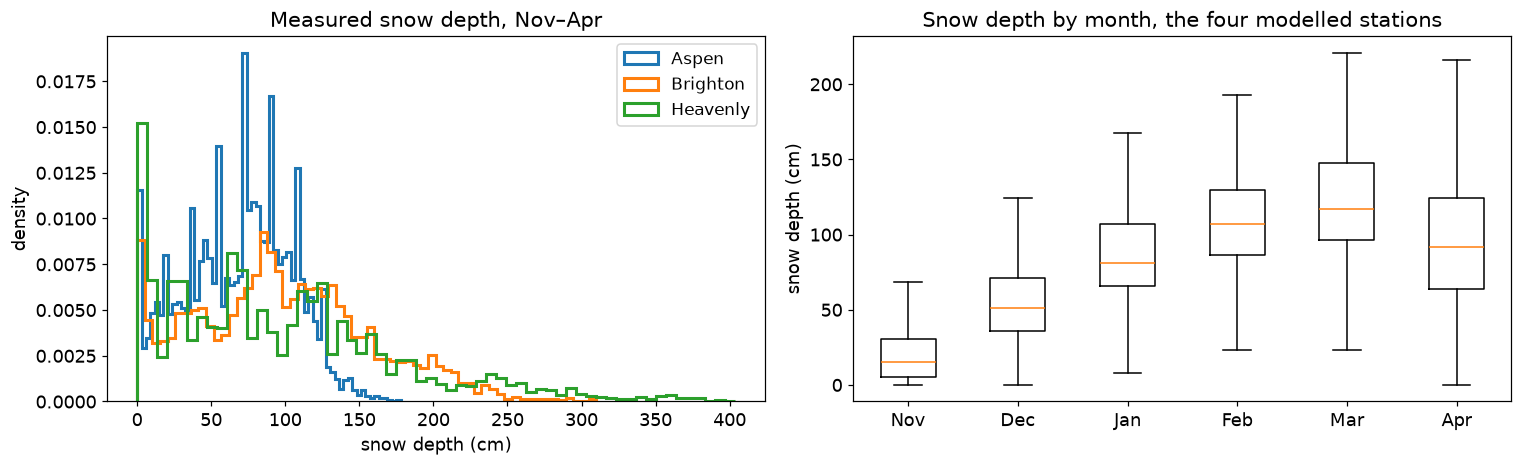

,days,pct_zero,median,max,skew
station_name,,,,,
Brighton,5256,2.3,94.0,309.9,0.4
Brumley,4110,2.1,73.7,175.3,-0.2
Heavenly Valley,4894,7.1,81.3,403.9,1.0
Kiln,4140,2.1,71.1,177.8,0.0


In [28]:
tg = out[out.in_season & out.SNWD_cm.notna() & ~out.SNWD_imputed & out.station.isin(STATIONS)]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for r, c in RES.items():
    axes[0].hist(tg[tg.station.isin(c["stations"])].SNWD_cm, bins=60, histtype="step", lw=2, density=True, label=r)
axes[0].set_title("Measured snow depth, Nov–Apr"); axes[0].set_xlabel("snow depth (cm)"); axes[0].set_ylabel("density"); axes[0].legend()
months = [11, 12, 1, 2, 3, 4]
axes[1].boxplot([tg[tg.date.dt.month == k].SNWD_cm for k in months], tick_labels=["Nov", "Dec", "Jan", "Feb", "Mar", "Apr"], showfliers=False)
axes[1].set_title("Snow depth by month, the four modelled stations"); axes[1].set_ylabel("snow depth (cm)")
fig.tight_layout(); savefig(fig, "target_distribution"); plt.show()
tg.groupby("station_name").SNWD_cm.agg(days="size", pct_zero=lambda s: 100 * (s == 0).mean(), median="median", max="max", skew="skew").round(1)

Zero depths are rare (2–7 % of days), and only Heavenly has a long right tail (skew 1.0). The bigger feature is that depth
depends strongly on the month. So we will report MAE overall and by month, and we will not treat zero as a special class.

### 3.9 Scale of the features
Snow depth runs to hundreds of cm, while temperature is a few tens of degrees around zero. The modelling features (§4.3)
range from ±1 and 0/1 flags to season totals above 1,000. So regularised linear regression needs standardised inputs,
and random forests do not. **Any scaler is fitted on training winters only.**

In [29]:
out[VALUE_COLS].describe(percentiles=[.01, .5, .99]).T.round(1)

,count,mean,std,min,1%,50%,99%,max
SNWD_cm,170866.0,59.3,74.8,0.0,0.0,25.4,304.8,505.5
WTEQ_cm,285426.0,19.8,29.9,0.0,0.0,6.4,133.9,295.9
TAVG_C,240686.0,1.8,8.8,-31.3,-17.1,1.6,18.3,28.2
TMAX_C,240183.0,9.2,9.6,-25.8,-11.0,9.1,27.2,37.8
TMIN_C,240831.0,-4.1,8.8,-36.4,-24.6,-3.4,13.5,20.9
PRCP_mm,284199.0,2.7,6.6,0.0,0.0,0.0,30.5,228.6
PREC_mm,284281.0,566.0,483.6,0.0,0.0,477.5,2339.3,3403.6


### 3.10 Information leakage
| Risk | Where it could enter | How we handle it |
|---|---|---|
| Future data in features | lags, rolling windows | features for day *t* use only rows dated ≤ *t*; unit tests truncate and perturb the future to prove it (`tests/test_modeltable.py`) |
| Test winters in the baseline | climatology | fitted on training winters only; a unit test poisons the test winters to prove it (staff condition) |
| NRCS 30-year normals | `centralTendencyType` | never requested (D-010) |
| Scalers or imputation fitted on all data | standardisation, gap filling | scalers are fitted on training winters only; filled values are past readings, but *whether* a gap is filled depends on when it ends (§3.5, D-038) |
| Post-hoc NRCS edits | `value` vs `orig_value` | see below |

**Post-hoc edits (D-024).** On a real forecast date, a forecaster would see only the raw, provisional reading. The `value`
we train on has often been edited by NRCS weeks or months later. So our "today's snow depth" feature is a little cleaner than it could really be:

In [30]:
ed = sn[sn.element.isin(["SNWD", "WTEQ"]) & sn.value.notna() & sn.orig_value.notna()]
edited = ed.value != ed.orig_value
print("Share of values NRCS changed after the reading (%):", edited.groupby(ed.element).mean().mul(100).round(1).to_dict())
print("Median size of an edit (in):", (ed.value - ed.orig_value)[edited].abs().groupby(ed.element[edited]).median().to_dict())

Share of values NRCS changed after the reading (%): {'SNWD': 29.2, 'WTEQ': 33.7}
Median size of an edit (in): {'SNWD': 1.0, 'WTEQ': 0.2}


Milestone 3 will therefore include a robustness run with features rebuilt from the original readings. All of those
features must be rebuilt, not just today's depth (CODE_AUDIT A-03, D-038).

## 4. The modelling table
**One row = (resort, issue date *t*).** The columns are what a forecaster knows at the end of day *t*. The target is
**measured snow depth on day *t* + 30**.

### 4.1 One daily series per resort, and the Aspen composite (D-008)
Brighton and Heavenly use their single station. Aspen is the mean of Kiln and Brumley **on days both report**, and NaN
otherwise, so the set of stations never changes over time. A day counts as **measured** only if no member value was
filled in §3.5. Only measured days can be targets or scoring truth. Weather for Aspen is the mean of the two stations'
Open-Meteo requests (D-031).

in-season days 2004–2026: 4,169; both stations present: 4,120; r(Kiln, Brumley) = 0.940


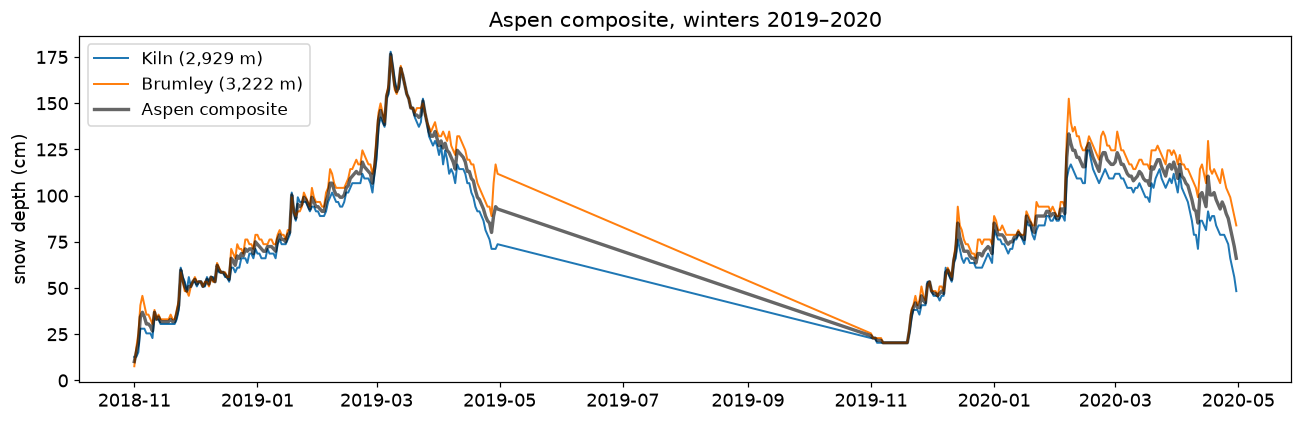

In [31]:
S = {r: mt.resort_snotel(out, c["stations"]) for r, c in RES.items()}
W = {r: mt.resort_weather([F[t] for t in c["stations"]]) for r, c in RES.items()}

a = pd.DataFrame({"Kiln": out[out.station == "556:CO:SNTL"].set_index("date").SNWD_cm,
                  "Brumley": out[out.station == "369:CO:SNTL"].set_index("date").SNWD_cm}).loc["2003-07-01":"2026-06-30"]
a = a[a.index.month.isin(mt.SEASON_MONTHS)]
both = a.dropna()
print(f"in-season days 2004–2026: {len(a):,}; both stations present: {len(both):,}; "
      f"r(Kiln, Brumley) = {both.Kiln.corr(both.Brumley):.3f}")
s = a.loc["2018-10-01":"2020-06-30"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(s.index, s.Kiln, lw=1.3, label="Kiln (2,929 m)"); ax.plot(s.index, s.Brumley, lw=1.3, label="Brumley (3,222 m)")
ax.plot(s.index, S["Aspen"].snwd.reindex(s.index), lw=2.2, color="k", alpha=.6, label="Aspen composite")
ax.set_title("Aspen composite, winters 2019–2020"); ax.set_ylabel("snow depth (cm)"); ax.legend()
fig.tight_layout(); savefig(fig, "aspen_composite"); plt.show()

### 4.2 Features: what is known at the end of day *t* (D-031)
`modeltable.build_features` computes every feature from rows dated ≤ *t* only:
- day-*t* values;
- backward differences;
- 7- and 30-day trailing windows;
- running totals since Oct 1.

Windows are strict: one missing day gives NaN, never a partial sum. There is no weather after day *t*, because no
archived forecasts exist (D-004). Temperatures come from Open-Meteo, because SNOTEL temperature sensors drift (D-031; DATA_SOURCES §2.0c).

In [32]:
D = {r: W[r].join(S[r], how="left").loc[sources.FEATURE_START:sources.FEATURE_END] for r in RES}
assert all(len(d) == len(full) for d in D.values()), "weather calendar must be complete"
FCOLS = list(mt.build_features(D["Aspen"]).columns)
FEAT_DICT = mt.feature_dictionary(FCOLS)
print(f"{len(FCOLS)} features:", FEAT_DICT.group.value_counts().to_dict())
FEAT_DICT

51 features: {'weather, trailing': 22, 'snow state': 11, 'weather, day t': 7, 'calendar': 4, 'reanalysis snow': 4, 'weather, season-to-date': 3}


,column,group,source,definition,unit
0,dowy,calendar,—,"days since Oct 1 of the water year, at issue d...",d
1,target_dowy,calendar,—,dowy + 30 (the target's day of season; used to...,d
2,doy_sin,calendar,—,sin/cos of 2π·day-of-year/365.25,—
3,doy_cos,calendar,—,sin/cos of 2π·day-of-year/365.25,—
4,snwd_t,snow state,SNOTEL,snow depth at end of day t (cleaned; ≤3-day ca...,cm
5,wteq_t,snow state,SNOTEL,snow-water equivalent at end of day t,cm
6,snwd_t_imputed,snow state,SNOTEL,1 if snwd_t was forward-filled (D-022),0/1
7,d_snwd_7,snow state,SNOTEL,snwd_t − snwd_(t−7),cm
8,d_wteq_7,snow state,SNOTEL,wteq_t − wteq_(t−7),cm
9,prcp_sum_7,snow state,SNOTEL,"station precipitation, sum over t−7+1..t (strict)",mm


### 4.3 Labels and rows (D-029)
`modeltable.labels` is the **only** code that looks ahead: it reads snow depth on *t* + 30. A row is kept if its target
date falls in Nov 1 – Apr 30, so issue dates run from Oct 2 to Mar 31. A row is a **usable label** only if its target
is measured.

In [33]:
T = pd.concat([mt.model_table(D[r], r, c["first_winter"], sites.LAST_WINTER) for r, c in RES.items()])
print(f"modelling table: {T.shape[0]:,} rows × {T.shape[1] + 1} columns (incl. the issue date) | dtypes {T.dtypes.value_counts().to_dict()}")
FEATS = [c for c in FCOLS if c != "target_dowy"]    # target_dowy = dowy + 30: only for looking up climatology
FUNNEL = pd.DataFrame({r: {"rows (target date Nov–Apr)": len(g), "target measured": int(g.y_measured.sum()),
                           "+ snow depth known at t": int((g.y_measured & g.snwd_t.notna()).sum()),
                           "+ every feature present": len(g[g.y_measured].dropna(subset=FEATS))}
                       for r, g in T.groupby("resort", sort=False)})
FUNNEL

modelling table: 14,319 rows × 58 columns (incl. the issue date) | dtypes {dtype('float64'): 50, dtype('int64'): 3, <StringDtype(na_value=nan)>: 2, dtype('<M8[us]'): 1, dtype('bool'): 1}


,Aspen,Brighton,Heavenly
rows (target date Nov–Apr),4169,5256,4894
target measured,4081,5256,4894
+ snow depth known at t,4036,5251,4894
+ every feature present,3747,5221,4894


Range of every feature on training winters (the feature-scale check in §3.9):

In [34]:
T.loc[T.split == "train", FEATS].describe().T[["mean", "std", "min", "max"]].round(1)

,mean,std,min,max
dowy,91.1,52.3,1.0,182.0
doy_sin,0.0,0.7,-1.0,1.0
doy_cos,0.6,0.3,0.0,1.0
snwd_t,72.4,60.2,0.0,363.2
wteq_t,20.5,19.9,0.0,110.0
snwd_t_imputed,0.0,0.1,0.0,1.0
d_snwd_7,5.0,17.0,-73.7,116.8
d_wteq_7,1.8,2.9,-8.9,23.1
prcp_sum_7,20.9,25.3,0.0,195.6
d_snwd_30,22.0,28.7,-94.0,157.5


Nothing is imputed to keep rows. Most of the complete-case losses come from gaps in SNOTEL precipitation
(`prcp_sum_*`), which wipe out Aspen's whole 2021 winter. D-040 proposes dropping those two features, because
Open-Meteo precipitation already covers them.

### 4.4 Split by winter (D-032)
| split | winters (labelled by the year the season ends) | used for |
|---|---|---|
| **train** | first winter – 2016 | fitting models, climatology, scalers |
| **validation** | 2017–2020 | choosing models and settings; cross-validation folds are whole winters (D-033) |
| **test** | 2021–2026 | **touched once**, after all choices are frozen |

The staff require testing on later winters, never a random split. Consecutive days are near-duplicates, so a random
split would put near-copies of test rows into training. All resorts share one calendar, so they are tested on the same
winters, and a summer separates every pair of winters, so no 30-day target crosses a split boundary.

An earlier exploratory notebook already scored baselines on the test winters, so they are not strictly unseen. We disclose that, and from here
on every choice uses train and validation only (D-039). The plot below therefore shows only those winters.

winters  first  last  rows  usable_labels
resort   split                                           
Aspen    train       13   2004  2016  2357           2269
         val          4   2017  2020   725            725
         test         6   2021  2026  1087           1087
Brighton train       19   1998  2016  3444           3444
         val          4   2017  2020   725            725
         test         6   2021  2026  1087           1087
Heavenly train       17   2000  2016  3082           3082
         val          4   2017  2020   725            725
         test         6   2021  2026  1087           1087

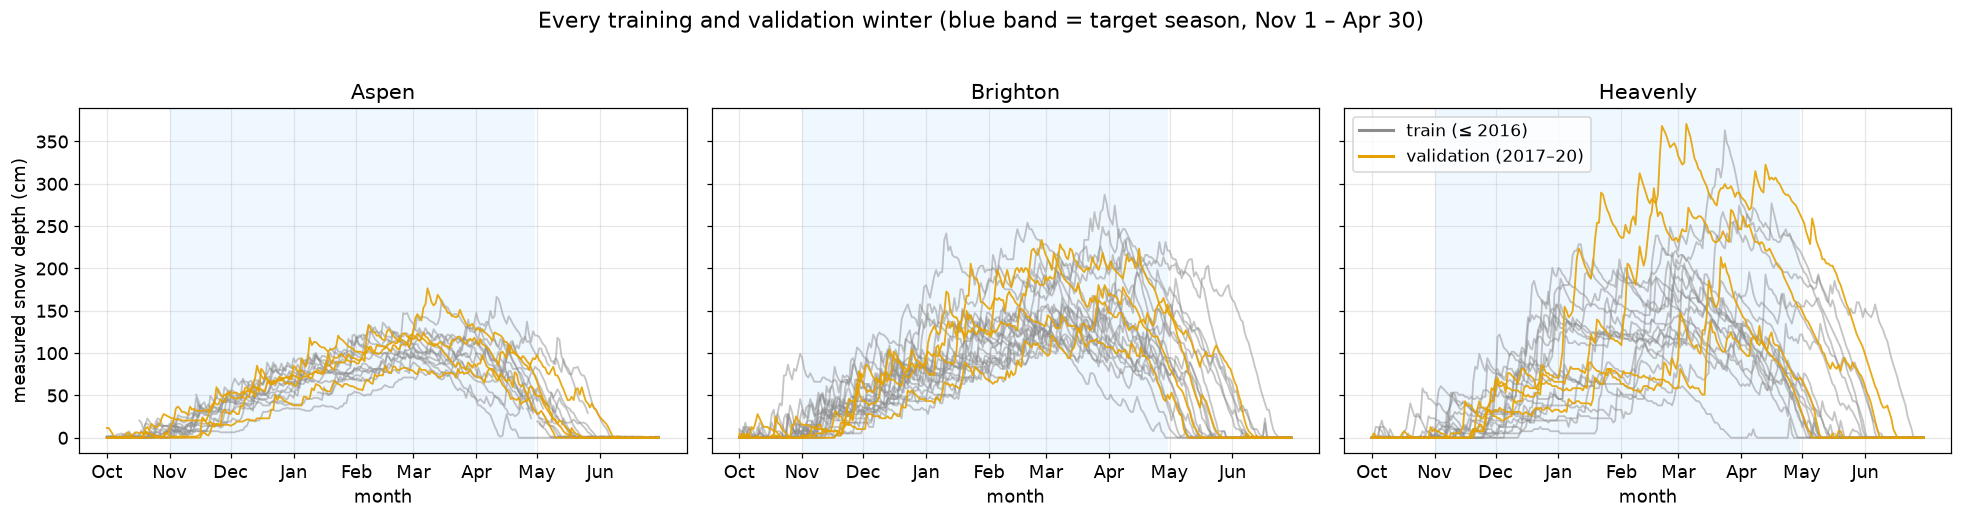

In [35]:
display(T.groupby(["resort", "split"]).agg(winters=("winter", "nunique"), first=("winter", "min"), last=("winter", "max"),
                                         rows=("y", "size"), usable_labels=("y_measured", "sum")).reindex(["train", "val", "test"], level=1))

SPLIT_COL = {"train": "#8c8c8c", "val": "#e6a100"}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), sharey=True)
for ax, (r, c) in zip(axes, RES.items()):
    s = S[r].assign(winter=parse.winter_of(S[r].index), dowy=mt.day_of_water_year(S[r].index))
    s = s[(s.dowy <= 272) & s.winter.between(c["first_winter"], 2020)]
    for wtr, g in s.groupby("winter"):
        sp = mt.split_of([wtr])[0]
        ax.plot(g.dowy, g.snwd.where(g.snwd_measured), color=SPLIT_COL[sp], lw=1.2, alpha=.5 if sp == "train" else .9)
    ax.axvspan(31, 211, color="#cfe8ff", alpha=.3, lw=0)
    ax.set_xticks([0, 31, 61, 92, 123, 151, 182, 212, 243], ["Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May", "Jun"])
    ax.set_title(r); ax.set_xlabel("month"); ax.grid(alpha=.3)
axes[0].set_ylabel("measured snow depth (cm)")
axes[2].legend([plt.Line2D([], [], color=v, lw=2) for v in SPLIT_COL.values()], ["train (≤ 2016)", "validation (2017–20)"])
fig.suptitle("Every training and validation winter (blue band = target season, Nov 1 – Apr 30)", y=1.02)
fig.tight_layout(); savefig(fig, "seasonal_curves"); plt.show()

Winters differ hugely in snow amount and timing, so one average seasonal curve leaves large errors. Within a winter,
though, depth changes smoothly, which is why today's depth carries information.

**Why not a random split? (D-033)** Consecutive days are near-duplicates: the target on day *t* + 1 is almost the target on
day *t*. Below we score the same ridge regression two ways, with 5 shuffled folds and with 5 folds of whole winters,
on **train + validation winters only**, so the test winters stay untouched. The ridge model is only a demonstration,
not our model.

In [36]:
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rows = []
for r, g in T[T.split.isin(["train", "val"]) & T.y_measured].dropna(subset=FEATS).groupby("resort", sort=False):
    X, y = g[FEATS].to_numpy(), g.y.to_numpy()
    model = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 12)))
    mae = lambda cv, **kw: np.abs(cross_val_predict(model, X, y, cv=cv, **kw) - y).mean()
    rows.append({"resort": r, "rows": len(g), "MAE, random 5-fold (cm)": mae(KFold(5, shuffle=True, random_state=0)),
                 "MAE, 5 folds of whole winters (cm)": mae(GroupKFold(5), groups=g.winter.to_numpy())})
RS = pd.DataFrame(rows).set_index("resort")
RS["random split looks better by (%)"] = 100 * (1 - RS.iloc[:, 1] / RS.iloc[:, 2])
RS.round(1)

,rows,"MAE, random 5-fold (cm)","MAE, 5 folds of whole winters (cm)",random split looks better by (%)
resort,,,,
Aspen,2841,11.3,15.0,24.4
Brighton,4134,19.1,22.5,14.9
Heavenly,3807,27.8,33.6,17.2


The random split makes the same model look 15–24 % better than it is, because it is partly tested on near-copies of
its training rows. Grouping by winter gives the honest estimate, and it is how we will tune models in Milestone 3.

### 4.5 The baselines, on validation winters (D-035)
- **Climatology** (staff: "historical averages for the same time of year"). The mean measured depth for the target's day
  of season, pooled over ±7 days, from **training winters only**. `modeltable.climatology` drops every other winter
  before computing anything.
- **Persistence.** Depth in 30 days = depth today.
- **Persistence + climatological change.** Today's depth plus the change climatology expects over the next 30 days.

All three are scored on the same rows: measured target and known depth at *t*. Errors are in cm.

In [37]:
scores = []
for r in RES:
    tr = T[(T.resort == r) & (T.split == "train")]
    clim = mt.climatology(D[r], sorted(tr.winter.unique()))
    v = T[(T.resort == r) & (T.split == "val") & T.y_measured & T.snwd_t.notna()]
    preds = {"climatology": clim.reindex(v.target_dowy).to_numpy(), "persistence": v.snwd_t.to_numpy(),
             "persistence + clim. change": np.clip(v.snwd_t + clim.reindex(v.target_dowy).to_numpy() - clim.reindex(v.dowy).to_numpy(), 0, None)}
    for name, p in preds.items():
        err = p - v.y.to_numpy()
        scores.append({"resort": r, "baseline": name, "n": len(v), "MAE": np.abs(err).mean(),
                       "RMSE": np.sqrt((err ** 2).mean()), "bias": err.mean()})
BASELINES = pd.DataFrame(scores)
BASELINES.pivot(index="baseline", columns="resort", values="MAE").round(1)

resort,Aspen,Brighton,Heavenly
baseline,,,
climatology,16.9,28.1,56.5
persistence,24.1,31.7,44.0
persistence + clim. change,12.5,18.7,36.2


Neither climatology nor persistence wins at every resort, and combining them beats both everywhere. We will report this
combination too, as a harder bar than the two baselines named in the question.

### 4.6 Save the modelling table

In [38]:
SAVE = T.reset_index().rename(columns={"date": "issue_date"})
labels_dict = pd.DataFrame([
    ("issue_date", "label", "—", "issue date t (forecast made at end of day t)", "date"),
    ("resort", "label", "—", "resort (src/sites.py RESORTS)", ""),
    ("target_date", "label", "—", "t + 30 days (always Nov 1 – Apr 30)", "date"),
    ("y", "target", "SNOTEL", "snow depth at target_date (Aspen: Kiln+Brumley composite)", "cm"),
    ("y_measured", "target", "SNOTEL", "True if y is measured (not imputed, all members present): ONLY these rows are labels/truth", "bool"),
    ("winter", "label", "—", "season-end year of target_date (== that of issue_date)", ""),
    ("split", "label", "—", "train (≤2016) / val (2017–2020) / test (2021–2026), D-032", ""),
], columns=FEAT_DICT.columns)
table_dict = pd.concat([labels_dict, FEAT_DICT])
assert set(table_dict.column) == set(SAVE.columns)
SAVE.to_parquet(OUT / "model_table.parquet", index=False)
table_dict.to_csv(OUT / "model_table_columns.csv", index=False)
BASELINES.to_csv(OUT / "baseline_scores.csv", index=False)
for f in ["snotel_clean.parquet", "model_table.parquet"]:
    print(f"{f}: {(OUT / f).stat().st_size / 1e6:.1f} MB")

snotel_clean.parquet: 4.5 MB
model_table.parquet: 2.0 MB


## 5. The revised project question

> **For three ski areas in distinct snow climates (Aspen CO, from the Kiln + Brumley SNOTEL composite; Brighton UT; and
> Heavenly CA), can a regression model using only information available on day *t* predict SNOTEL-measured snow depth on
> day *t* + 30 (target dates Nov–Apr) with lower mean absolute error than (a) a day-of-season climatology computed from
> training winters only and (b) persistence, on the later winters 2021–2026?**

We will know it is answered when each resort's model has a test-winter MAE, scored on the same rows as the baselines.
The model then either beats each baseline or it does not.

**How it changed from the original proposal** (D-003, D-005):
- **Where:** three European resorts became three US resorts. SNOTEL gives free, long, daily, *measured* on-mountain snow depth; we found no free equivalent for the European resorts (DATA_SOURCES §3).
- **What we predict:** a weather-based "ski index" became measured snow depth. Reanalysis cannot resolve snow on a mountain (§1.3).
- The ski-condition index is now a secondary output (D-026).

**Staff conditions**

| Condition | How we meet it |
|---|---|
| Weather source is Open-Meteo, with a correct link | ERA5 / ERA5-Land from https://open-meteo.com/en/docs/historical-weather-api, models pinned (§1.3, §1.4) |
| Compare against historical averages for the same time of year | climatology baseline (§4.5) |
| Test on later winters | split by winter: train ≤ 2016, validation 2017–2020, test 2021–2026 (§4.4) |
| Averages from training years only | `modeltable.climatology` uses only the winters it is given, enforced by a unit test (§4.5) |